#telechargement du fichier

IMPORTS ET CHARGEMENT DES DONNÉES

In [255]:
import pandas as pd
import matplotlib.pyplot as plt  # bibliothèque pour dessiner des graphiques
import seaborn as sns   # bibliothèque de graphiques statistiques, bâtie sur matplotlib

df = pd.read_csv("../data/raw/credit_risk_dataset.csv")


les informations du fichier

In [256]:
df.head()
print(df.shape)
df.info()
df.describe()
df.dtypes

(32581, 12)
<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


person_age                      int64
person_income                   int64
person_home_ownership             str
person_emp_length             float64
loan_intent                       str
loan_grade                        str
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file         str
cb_person_cred_hist_length      int64
dtype: object

# valeur manquantes

Nombre de VALEURS MANQUANTES 

In [257]:
print("Nombre de valeurs manquantes par colonne :")
print(df.isna().sum())


Nombre de valeurs manquantes par colonne :
person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64


les pourcentages des valeurs maquantes


In [258]:
print((df.isna().mean() * 100).sort_values(ascending=False).round(2))

# Nombre de lignes qui sont la copie EXACTE d'une ligne déjà vue plus haut
print("\nNombre de lignes dupliquées :", df.duplicated().sum())

loan_int_rate                 9.56
person_emp_length             2.75
person_income                 0.00
person_age                    0.00
person_home_ownership         0.00
loan_intent                   0.00
loan_grade                    0.00
loan_amnt                     0.00
loan_status                   0.00
loan_percent_income           0.00
cb_person_default_on_file     0.00
cb_person_cred_hist_length    0.00
dtype: float64

Nombre de lignes dupliquées : 165


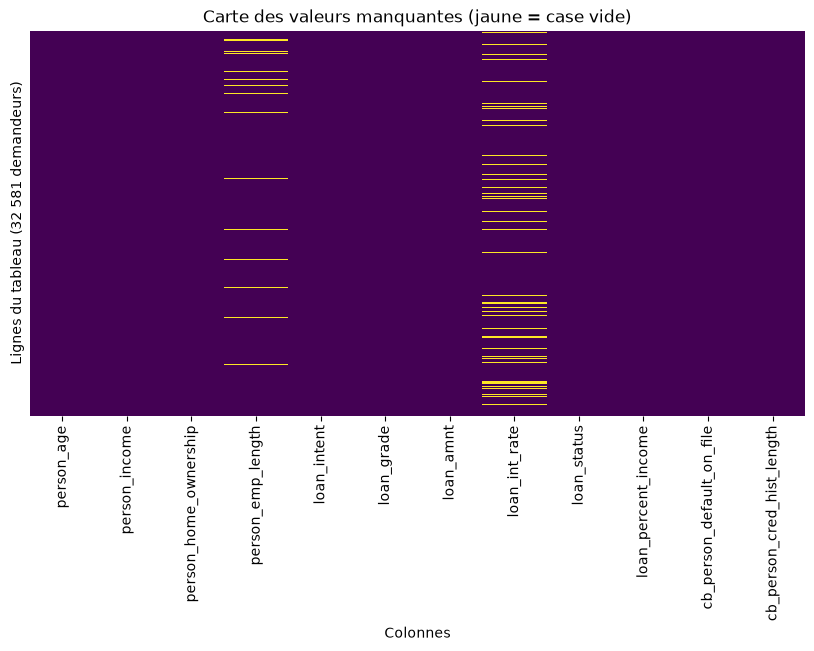

In [259]:

plt.figure(figsize=(10, 5))

# df.isna() donne un tableau de True/False de la même taille que df
# heatmap colorie chaque case : une couleur pour True (vide), une autre pour False (remplie)
# cbar=False        -> on cache la barre de légende des couleurs (inutile ici)
# yticklabels=False -> on n'écrit pas les 32 581 numéros de ligne
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap="viridis")

plt.title("Carte des valeurs manquantes (jaune = case vide)")
plt.xlabel("Colonnes")
plt.ylabel("Lignes du tableau (32 581 demandeurs)")
plt.show()

histogramme des valeur numérique 

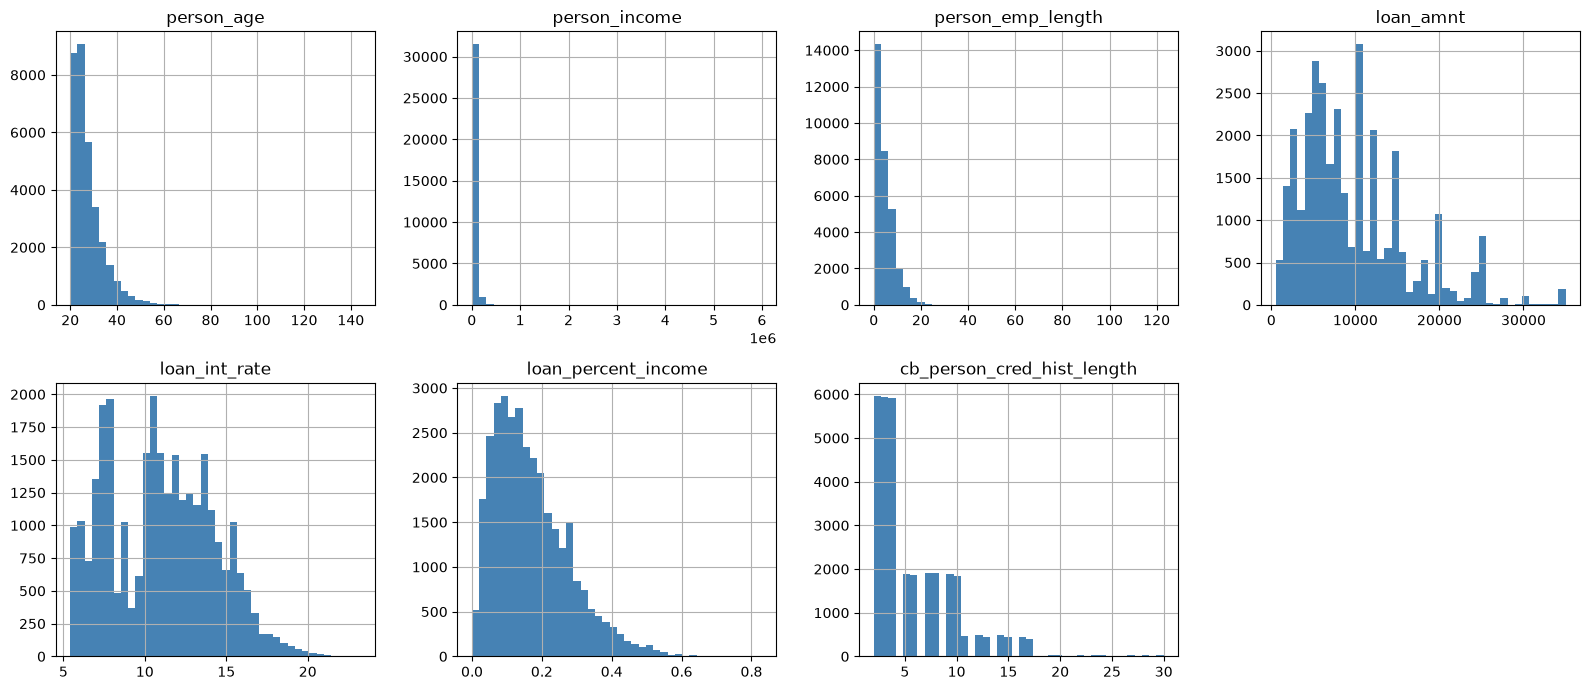

In [260]:
import matplotlib.pyplot as plt   # bibliothèque de graphiques

# Liste des colonnes numériques qu'on veut observer
colonnes_num = [
    "person_age", "person_income", "person_emp_length",
    "loan_amnt", "loan_int_rate", "loan_percent_income",
    "cb_person_cred_hist_length",
]

# On crée une grille de 2 lignes x 4 colonnes de petits graphiques
fig, axes = plt.subplots(2, 4, figsize=(16, 7))

# axes.flatten() transforme la grille en simple liste, pour la parcourir facilement
# zip() associe chaque colonne à un graphique : la 1re colonne au 1er graphique, etc.
for ax, col in zip(axes.flatten(), colonnes_num):
    # dropna() retire les cases vides (un histogramme ne peut pas les dessiner)
    # bins=40 : on découpe les valeurs en 40 tranches
    df[col].dropna().hist(bins=40, ax=ax, color="steelblue")
    ax.set_title(col)

# La grille a 8 cases pour 7 colonnes : on cache la dernière, restée vide
axes.flatten()[-1].axis("off")

plt.tight_layout()   # évite que les titres se chevauchent
plt.show()

diagramme en barre des valeur categorielle

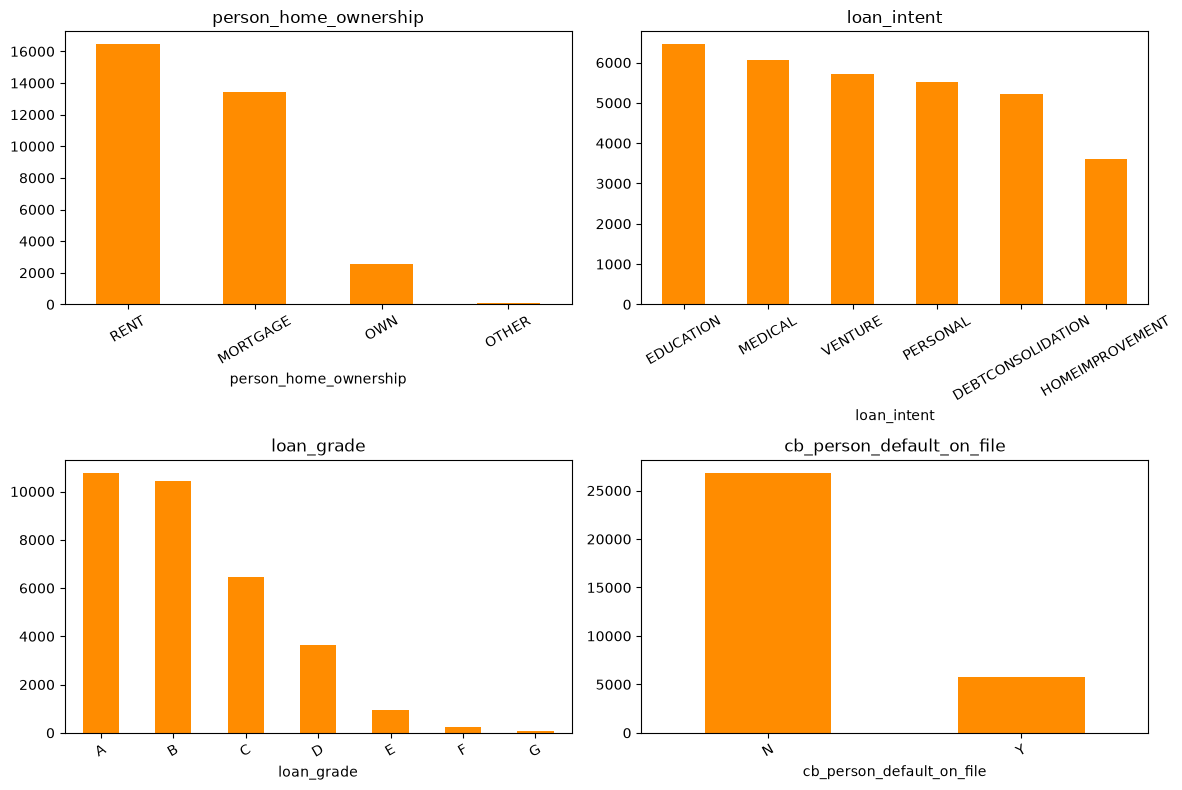

In [261]:
import matplotlib.pyplot as plt   # bibliothèque de graphiques

# Les 4 colonnes de texte (catégories)
colonnes_cat = [
    "person_home_ownership", "loan_intent",
    "loan_grade", "cb_person_default_on_file",
]

# Grille de 2 lignes x 2 colonnes de petits graphiques
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flatten(), colonnes_cat):
    # value_counts() compte combien de clients il y a dans chaque catégorie
    # plot.bar() dessine ces effectifs en barres
    df[col].value_counts().plot.bar(ax=ax, color="darkorange")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=30)   # incline les noms pour les lire

plt.tight_layout()   # évite que les titres se chevauchent
plt.show()

In [262]:
# Les deux colonnes qui ont des valeurs manquantes
cols_manquantes = ["person_emp_length", "loan_int_rate"]

# mean() = moyenne, median() = valeur du milieu (les cases vides sont ignorées)
# skew() = coefficient d'asymétrie :
#   proche de 0 -> symétrique
#   positif     -> queue vers la DROITE
#   négatif     -> queue vers la GAUCHE
resume = pd.DataFrame({
    "moyenne": df[cols_manquantes].mean(),
    "mediane": df[cols_manquantes].median(),
    "asymetrie": df[cols_manquantes].skew(),
})
print(resume.round(2))

                   moyenne  mediane  asymetrie
person_emp_length     4.79     4.00       2.61
loan_int_rate        11.01    10.99       0.21


**Conclusion sur les valeurs manquantes :** seules deux colonnes sont concernées,
`person_emp_length` (895 valeurs, environ 2,75 %) et `loan_int_rate` (3 116 valeurs,
environ 9,56 %). `person_emp_length` est fortement asymétrique à droite (asymétrie 2,61),
tandis que `loan_int_rate` est quasi symétrique (0,21). Dans les deux cas, on imputera par
la **médiane**, calculée sur le jeu d'entraînement uniquement, dans un Pipeline.

# Doublons

compter les doublons

In [263]:
print("Nombre de lignes dupliquées :", df.duplicated().sum())

Nombre de lignes dupliquées : 165


supprimé les doublons

In [264]:
# On garde la 1re copie de chaque ligne et on retire les suivantes
avant = len(df)
df = df.drop_duplicates().reset_index(drop=True)   # reset_index renumérote les lignes de 0 à n-1
print("Lignes avant :", avant)
print("Lignes après :", len(df))
print("Doublons restants :", df.duplicated().sum())   # doit afficher 0

Lignes avant : 32581
Lignes après : 32416
Doublons restants : 0


In [265]:
# Critères du PDF : âges et anciennetés supérieurs à 100 ans
print("Âge > 100 :", (df["person_age"] > 100).sum())
print("Ancienneté > 100 :", (df["person_emp_length"] > 100).sum())

# Les lignes concernées, pour les regarder
print(df[(df["person_age"] > 100) | (df["person_emp_length"] > 100)])

# Résumé statistique pour repérer les extrêmes
print(df[["person_age", "person_emp_length", "person_income"]].describe().round(1))

Âge > 100 : 5
Ancienneté > 100 : 2
       person_age  person_income person_home_ownership  person_emp_length  \
0              22          59000                  RENT              123.0   
81            144         250000                  RENT                4.0   
183           144         200000              MORTGAGE                4.0   
210            21         192000              MORTGAGE              123.0   
575           123          80004                  RENT                2.0   
747           123          78000                  RENT                7.0   
32132         144        6000000              MORTGAGE               12.0   

      loan_intent loan_grade  loan_amnt  loan_int_rate  loan_status  \
0        PERSONAL          D      35000          16.02            1   
81        VENTURE          C       4800          13.57            0   
183     EDUCATION          B       6000          11.86            0   
210       VENTURE          A      20000           6.54          

**Conclusion sur les doublons :** le jeu de données contenait 165 lignes dupliquées
(copies exactes d'une autre ligne), soit environ 0,5 % des 32 581 observations. Nous les
avons supprimées en conservant la première occurrence, ce qui ramène le jeu à 32 416 lignes.
Cette étape est faite avant le découpage entraînement/test : sinon, une même observation
pourrait se retrouver à la fois dans l'entraînement et dans le test, et le modèle semblerait
meilleur qu'il ne l'est réellement. Après nettoyage, il ne reste aucun doublon.

# Valeurs aberrantes

In [266]:

# Les trois colonnes qu'on veut contrôler
cols = ["person_age", "person_emp_length", "person_income"]

# agg() calcule plusieurs statistiques d'un coup :
#   min = la plus petite valeur, max = la plus grande, median = la valeur du milieu
# Les cases vides sont ignorées automatiquement
print(df[cols].agg(["min", "median", "max"]))

# --- Combien de lignes seraient touchées par TES règles ? (on ne supprime rien ici) ---
print("\nÂge < 18      :", (df["person_age"] < 18).sum())
print("Âge > 100     :", (df["person_age"] > 100).sum())
print("Ancienneté > 40 :", (df["person_emp_length"] > 50).sum())


        person_age  person_emp_length  person_income
min           20.0                0.0         4000.0
median        26.0                4.0        55000.0
max          144.0              123.0      6000000.0

Âge < 18      : 0
Âge > 100     : 5
Ancienneté > 40 : 2


In [267]:
# Clients dont l'ancienneté dépasse 40 ans
# On affiche leur âge à côté, pour juger si c'est plausible
cas = df[df["person_emp_length"] > 40][["person_age", "person_emp_length", "person_income"]]
print("Nombre de clients concernés :", len(cas))
print(cas)

# Test de cohérence : a-t-on commencé à travailler avant 14 ans ?
# âge - ancienneté = âge auquel la personne a commencé à travailler
cas_age_debut = df["person_age"] - df["person_emp_length"]
print("\nClients qui auraient commencé avant 14 ans :", (cas_age_debut < 14).sum())

Nombre de clients concernés : 3
       person_age  person_emp_length  person_income
0              22              123.0          59000
210            21              123.0         192000
32190          78               41.0          48000

Clients qui auraient commencé avant 14 ans : 2


compter et regarder les lignes incoherents

In [268]:
# ----- Les seuils, modifiables ici en un seul endroit -----
AGE_MIN = 20          # âge minimum du demandeur
AGE_MAX = 100         # âge maximum (seuil signalé par le PDF)
DEBUT_CARRIERE = 14   # âge le plus jeune auquel on a pu commencer à travailler

# Règle 1 : âge entre AGE_MIN et AGE_MAX inclus
# between() donne True si la valeur est dans l'intervalle
age_ok = df["person_age"].between(AGE_MIN, AGE_MAX)

# Règle 2 : l'ancienneté ne peut pas dépasser le nombre d'années
#           vécues depuis l'âge de début de carrière
# isna() | ... : une case vide est gardée, on l'imputera plus tard avec la médiane
emp_ok = df["person_emp_length"].isna() | (
    df["person_emp_length"] <= df["person_age"] - DEBUT_CARRIERE
)

# ~ veut dire "le contraire" : on compte les lignes qui VIOLENT chaque règle
print("Violent la règle d'âge        :", (~age_ok).sum())
print("Violent la règle d'ancienneté :", (~emp_ok).sum())
print("Total de lignes à supprimer   :", (~(age_ok & emp_ok)).sum())

# On regarde les lignes concernées avant de décider
df[~(age_ok & emp_ok)][["person_age", "person_emp_length", "person_income", "loan_status"]]

Violent la règle d'âge        : 5
Violent la règle d'ancienneté : 2
Total de lignes à supprimer   : 7


,person_age,person_emp_length,person_income,loan_status
0,22,123.0,59000,1
81,144,4.0,250000,0
183,144,4.0,200000,0
210,21,123.0,192000,0
575,123,2.0,80004,0
747,123,7.0,78000,0
32132,144,12.0,6000000,0


supprimer et vérifier les incoherences d'apres notre regle metier

In [269]:
# On ne garde que les lignes qui respectent LES DEUX règles
avant = len(df)
df = df[age_ok & emp_ok].reset_index(drop=True)   # reset_index renumérote de 0 à n-1
print("Lignes avant :", avant)
print("Lignes après :", len(df))
print("Supprimées   :", avant - len(df))

# Vérification : les minimums et maximums doivent maintenant être plausibles
print(df[["person_age", "person_emp_length", "person_income"]].agg(["min", "max"]))

Lignes avant : 32416
Lignes après : 32409
Supprimées   : 7
     person_age  person_emp_length  person_income
min          20                0.0           4000
max          94               41.0        2039784


Conclusion sur les Valeurs aberrantes : nous avons retenu les âges entre 20 et 100 ans (seuil du cahier des
charges) et exigé une ancienneté cohérente avec l'âge (début de carrière au plus tôt à 14 ans).
7 lignes sur 32 416 (environ 0,02 %) ont été supprimées : 5 âges de 123 à 144 ans et 2 anciennetés
de 123 ans pour des clients de 21 et 22 ans. Ce sont des erreurs de saisie évidentes. Ces règles
métier ne dépendent d'aucune statistique des données, il n'y a donc pas de risque de fuite avant
le split.

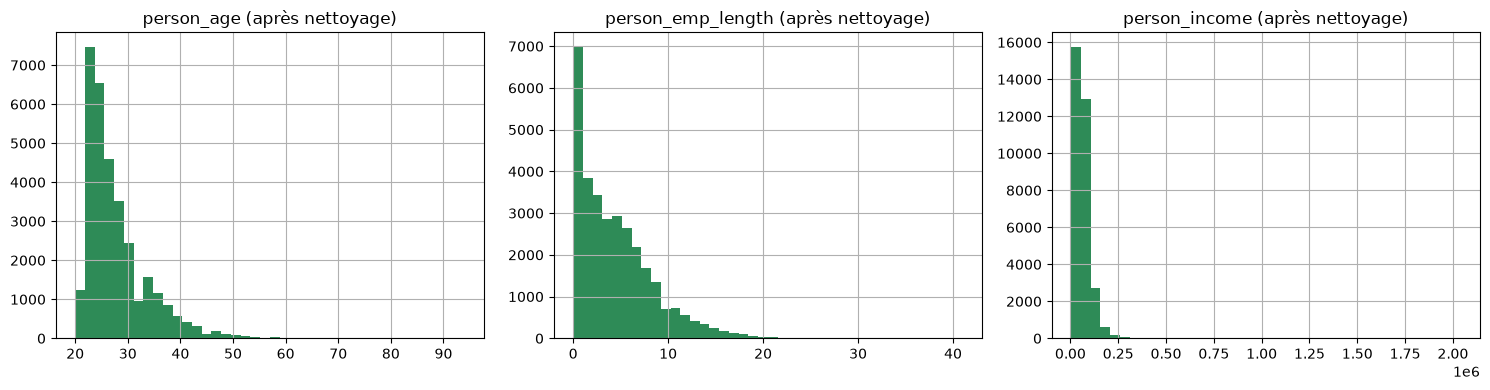

In [270]:
import matplotlib.pyplot as plt   # bibliothèque de graphiques

# Les 3 variables dont on a corrigé ou surveillé les extrêmes
colonnes = ["person_age", "person_emp_length", "person_income"]

# Une ligne de 3 petits graphiques côte à côte
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, colonnes):
    # dropna() retire les cases vides (un histogramme ne peut pas les dessiner)
    # bins=40 : on découpe les valeurs en 40 tranches
    df[col].dropna().hist(bins=40, ax=ax, color="seagreen")
    ax.set_title(col + " (après nettoyage)")

plt.tight_layout()   # évite que les titres se chevauchent
plt.show()

In [271]:
# Les 7 variables numériques
colonnes_num = [
    "person_age", "person_income", "person_emp_length",
    "loan_amnt", "loan_int_rate", "loan_percent_income",
    "cb_person_cred_hist_length",
]

# groupby("loan_status") sépare les clients en deux groupes : 0 (remboursé) et 1 (défaut)
# median() calcule la valeur du milieu de chaque variable, groupe par groupe
# On utilise la médiane plutôt que la moyenne : elle n'est pas tirée par les valeurs extrêmes
# .T transpose le tableau pour le lire plus facilement
tableau = df.groupby("loan_status")[colonnes_num].median().T

# Colonne de comparaison : de combien le groupe "défaut" est-il au-dessus ou en dessous ?
tableau["ecart_%"] = ((tableau[1] - tableau[0]) / tableau[0] * 100).round(1)

print(tableau.round(2))

loan_status                        0         1  ecart_%
person_age                     26.00     26.00      0.0
person_income               60000.00  41655.00    -30.6
person_emp_length               4.00      3.00    -25.0
loan_amnt                    8000.00   9600.00     20.0
loan_int_rate                  10.59     13.49     27.4
loan_percent_income             0.13      0.24     84.6
cb_person_cred_hist_length      4.00      4.00      0.0


**Relation avec la cible `loan_status` :** les clients en défaut ont, en médiane, un prêt
qui pèse davantage dans leur revenu (`loan_percent_income` : 0,24 contre 0,13, soit +85 %),
un revenu plus faible (41 655 contre 60 000, soit −31 %) et un taux d'intérêt plus élevé
(13,49 % contre 10,59 %, soit +27 %). L'âge et la durée d'historique de crédit ne
distinguent pas les deux groupes. Ces écarts sont des associations, pas des causes. Le
taux d'intérêt étant fixé à l'octroi, sa disponibilité au moment de la décision est
discutée dans la fiche de cadrage (risque de fuite de données).

In [272]:
# Les 4 colonnes de texte (catégories)
colonnes_cat = [
    "person_home_ownership", "loan_intent",
    "loan_grade", "cb_person_default_on_file",
]

for col in colonnes_cat:
    # groupby(col) range les clients par catégorie
    # mean() sur loan_status (0 ou 1) donne la proportion de défauts : le taux de défaut
    # * 100 : pourcentage ; sort_values : de la catégorie la plus risquée à la moins risquée
    taux = (df.groupby(col)["loan_status"].mean() * 100).sort_values(ascending=False).round(1)
    print(col)
    print(taux)
    print()

person_home_ownership
person_home_ownership
RENT        31.6
OTHER       31.1
MORTGAGE    12.6
OWN          7.5
Name: loan_status, dtype: float64

loan_intent
loan_intent
DEBTCONSOLIDATION    28.7
MEDICAL              26.8
HOMEIMPROVEMENT      26.2
PERSONAL             19.9
EDUCATION            17.3
VENTURE              14.9
Name: loan_status, dtype: float64

loan_grade
loan_grade
G    98.4
F    70.5
E    64.5
D    59.0
C    20.8
B    16.3
A    10.0
Name: loan_status, dtype: float64

cb_person_default_on_file
cb_person_default_on_file
Y    37.9
N    18.4
Name: loan_status, dtype: float64



In [273]:
# Pour chaque colonne de catégories, on veut DEUX informations par catégorie :
#   - le nombre de clients (effectif)
#   - le taux de défaut (moyenne de loan_status, en pourcentage)
for col in ["person_home_ownership", "loan_intent", "loan_grade", "cb_person_default_on_file"]:
    # agg() calcule plusieurs statistiques d'un coup sur loan_status
    # "count" = nombre de lignes, "mean" = moyenne (donc proportion de défauts)
    resume = df.groupby(col)["loan_status"].agg(["count", "mean"])

    # La moyenne passe en pourcentage, arrondie à 1 décimale
    resume["taux_defaut_%"] = (resume["mean"] * 100).round(1)

    # On garde seulement les deux colonnes utiles, triées par taux décroissant
    print(col)
    print(resume[["count", "taux_defaut_%"]].sort_values("taux_defaut_%", ascending=False))
    print()

person_home_ownership
                       count  taux_defaut_%
person_home_ownership                      
RENT                   16374           31.6
OTHER                    106           31.1
MORTGAGE               13366           12.6
OWN                     2563            7.5

loan_intent
                   count  taux_defaut_%
loan_intent                            
DEBTCONSOLIDATION   5189           28.7
MEDICAL             6042           26.8
HOMEIMPROVEMENT     3594           26.2
PERSONAL            5496           19.9
EDUCATION           6409           17.3
VENTURE             5679           14.9

loan_grade
            count  taux_defaut_%
loan_grade                      
G              64           98.4
F             241           70.5
E             963           64.5
D            3619           59.0
C            6436           20.8
B           10384           16.3
A           10702           10.0

cb_person_default_on_file
                           count  taux_defaut

In [274]:
# On regarde loan_grade seul : 7 lignes, de A à G
# count = nombre de clients, mean = proportion de défauts
resume = df.groupby("loan_grade")["loan_status"].agg(["count", "mean"])

# La proportion devient un pourcentage, arrondi à 1 décimale
resume["taux_defaut_%"] = (resume["mean"] * 100).round(1)

# Pas de tri : on garde l'ordre A, B, C... pour voir la progression du grade
print(resume[["count", "taux_defaut_%"]])

            count  taux_defaut_%
loan_grade                      
A           10702           10.0
B           10384           16.3
C            6436           20.8
D            3619           59.0
E             963           64.5
F             241           70.5
G              64           98.4


In [275]:
# Pour chaque grade (A à G), on calcule la médiane du taux d'intérêt
# median() ignore automatiquement les cases vides de loan_int_rate
# agg() permet aussi de compter les taux connus : "count" ne compte que les cases remplies
resume = df.groupby("loan_grade")["loan_int_rate"].agg(["count", "median", "min", "max"])
print(resume.round(2))

            count  median    min    max
loan_grade                             
A            9712    7.49   5.42   9.63
B            9335   10.99   6.00  12.69
C            5807   13.48   6.00  16.11
D            3308   15.31   6.00  18.49
E             880   16.82   6.00  20.69
F             214   18.54  15.01  22.06
G              59   20.16  17.34  23.22


**Relation avec la cible, variables catégorielles :** le taux de défaut (environ 22 % sur
l'ensemble) varie fortement selon les catégories. Les locataires (RENT, 31,6 %) sont environ
quatre fois plus souvent en défaut que les propriétaires (OWN, 7,5 %). Le motif
DEBTCONSOLIDATION (28,7 %) est le plus risqué, VENTURE (14,9 %) le moins. Un défaut antérieur
(`cb_person_default_on_file` = Y) double presque le risque (37,9 % contre 18,4 %).
`loan_grade` est de loin la plus discriminante : le taux passe de 10,0 % (grade A) à 98,4 %
(grade G), avec un saut net entre C (20,8 %) et D (59,0 %). Les catégories OTHER (106 clients)
et G (64 clients) reposent sur de petits effectifs, leurs taux sont peu fiables. Comme le
grade est attribué par la banque à l'octroi, il présente un risque de fuite de données,
discuté dans la fiche de cadrage.

In [276]:
# On ne garde que les clients dont le taux est connu (on ne peut pas mesurer une erreur sans valeur)
sous = df.dropna(subset=["loan_int_rate"])

# Pour chaque client, la moyenne du taux de son grade
# transform("mean") met cette moyenne sur chaque ligne, au lieu d'une seule ligne par grade
moy_grade = sous.groupby("loan_grade")["loan_int_rate"].transform("mean")

# Erreur de la "prédiction par le grade" : somme des écarts au carré entre le vrai taux et la moyenne du grade
erreur = ((sous["loan_int_rate"] - moy_grade) ** 2).sum()

# Variation totale du taux : somme des écarts au carré entre chaque taux et la moyenne générale
total = ((sous["loan_int_rate"] - sous["loan_int_rate"].mean()) ** 2).sum()

# R2 = part de la variation du taux que le grade explique (0 = rien, 1 = tout)
r2 = 1 - erreur / total
print("R2 du taux expliqué par le grade seul :", round(r2, 3))

R2 du taux expliqué par le grade seul : 0.903


## Fuite de données (data leakage)

**Définition.** Il y a fuite de données quand le modèle reçoit, pendant l'entraînement, une
information qu'il n'aurait pas au moment de prédire, ou qui contient déjà la réponse. Le score
obtenu paraît très bon, mais il ne vaut rien pour de nouveaux clients.

**Question de contrôle appliquée à chaque variable :** *cette information est-elle connue au
moment où le client fait sa demande de prêt ?*

### Ce que montrent les données

| Observation | Résultat |
|---|---|
| Taux de défaut par `loan_grade` | de 10,0 % (grade A) à 98,4 % (grade G), avec un saut net entre C (20,8 %) et D (59,0 %) |
| Taux d'intérêt médian par `loan_grade` | de 7,49 % (A) à 20,16 % (G), croissant à chaque grade |
| R² du taux expliqué par le grade seul | **0,903** |

Le grade explique environ 90 % de la variation du taux d'intérêt. Aucune autre variable ne
s'en approche (voir le tableau des médianes par groupe). Ce R² est calculé sur l'ensemble des
données : il sert à diagnostiquer un lien, ce n'est pas la performance d'un modèle.

### Analyse variable par variable

| Variable | Connue à la demande ? | Décision |
|---|---|---|
| `person_age`, `person_income`, `person_emp_length`, `person_home_ownership` | Oui (déclarées par le client) | Conservée |
| `loan_amnt`, `loan_intent`, `loan_percent_income` | Oui (le client les demande) | Conservée |
| `cb_person_default_on_file`, `cb_person_cred_hist_length` | Oui (bureau de crédit) | Conservée |
| `loan_grade` | Non : attribué par la banque après évaluation du risque | **Exclue** (régression et classification, à tester avec et sans) |
| `loan_int_rate` | Non : fixé par la banque à l'octroi | **Exclue** de la classification (c'est la cible en régression) |

### Conséquences pour la modélisation

- **Régression** (cible `loan_int_rate`) : `loan_grade` donne presque la réponse. Un R² très
  élevé avec cette variable sera questionné. Chaque modèle sera entraîné avec puis sans le
  grade, pour mesurer la chute du score.
- **Classification** (cible `loan_status`) : `loan_grade` et `loan_int_rate` sont fixés à
  l'octroi. Leur disponibilité au moment de la décision est discutée, et les modèles seront
  comparés avec et sans ces deux variables.
- **Préparation des données** : le découpage entraînement/test est fait **avant** l'imputation
  et la normalisation, qui sont ajustées sur l'entraînement seul dans un Pipeline, pour qu'aucune
  information du test ne passe dans l'apprentissage.

### Limite

Le moment exact où le grade est attribué n'est pas documenté dans le jeu de données : la
décision d'exclusion repose sur la logique métier d'une banque (évaluation du risque, puis
grade, puis taux) et sur l'indication du cahier des charges, pas sur une preuve statistique.

In [277]:
# Contrôle : df doit être le tableau NETTOYÉ, pas le tableau brut
print("Lignes dans df :", len(df))                      # attendu : 32409
print("Doublons restants :", df.duplicated().sum())    # attendu : 0
print("Âge max :", df["person_age"].max())             # attendu : 94

Lignes dans df : 32409
Doublons restants : 0
Âge max : 94


In [278]:
from sklearn.model_selection import train_test_split   # fonction qui sépare les données

RANDOM_STATE = 42   # la graine : même mélange à chaque exécution

# train_test_split coupe df en deux morceaux :
#   train = 80 % des clients (pour apprendre)
#   test  = 20 % des clients (pour vérifier, jamais utilisés pour apprendre)
# stratify : garde la même proportion de défauts (0 et 1) dans les deux morceaux
train, test = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df["loan_status"],
)

# Contrôles : tailles, et proportion de défauts dans chaque morceau
print("Taille totale :", len(df))
print("Train :", len(train), "| Test :", len(test))
print("\nTaux de défaut (loan_status = 1) :")
print("  Ensemble :", round(df["loan_status"].mean() * 100, 1), "%")
print("  Train    :", round(train["loan_status"].mean() * 100, 1), "%")
print("  Test     :", round(test["loan_status"].mean() * 100, 1), "%")

Taille totale : 32409
Train : 25927 | Test : 6482

Taux de défaut (loan_status = 1) :
  Ensemble : 21.9 %
  Train    : 21.9 %
  Test     : 21.9 %


In [279]:
# On enregistre les deux jeux dans des fichiers CSV
# index=False : on n'écrit pas la colonne des numéros de ligne (0, 1, 2...)
train.to_csv("../data/processed/train.csv", index=False)
test.to_csv("../data/processed/test.csv", index=False)

# Vérification : on relit les fichiers et on compare avec ce qu'on avait en mémoire
train_relu = pd.read_csv("../data/processed/train.csv")
test_relu = pd.read_csv("../data/processed/test.csv")

# shape = (nombre de lignes, nombre de colonnes) : doit être identique avant et après
print("Train :", train.shape, "->", train_relu.shape)
print("Test  :", test.shape, "->", test_relu.shape)

Train : (25927, 12) -> (25927, 12)
Test  : (6482, 12) -> (6482, 12)


In [280]:
# src/donnees.py
# Fonctions partagées par tous les notebooks du projet

import pandas as pd

# Les chemins sont écrits à un seul endroit : si on les change, tous les notebooks suivent
CHEMIN_TRAIN = "../data/processed/train.csv"
CHEMIN_TEST = "../data/processed/test.csv"


def charger_split():
    """Charge le split commun train/test sauvegardé par le notebook 01."""
    train = pd.read_csv(CHEMIN_TRAIN)
    test = pd.read_csv(CHEMIN_TEST)
    return train, test